# Introduction

This notebook continues the work from churn_data.ipynb, which handled the exploratory data analysis and the first preprocessing step. That step dropped 13 columns based on the exclusions set out in the proposal. The output, cleaned_churn_data.csv, is the starting point here.

This is the corrected version of the modelling notebook. Mrs Joosab's review found two validation problems in the first version. The preprocessing was fitted on the whole training set before the 5 fold cross validation, and SMOTE was applied to the whole training set before the cross validation as well. Both mistakes let information from the validation folds leak into the training side, which can make the cross validation scores too high and can change which hyperparameters get chosen.

What changed in this version:

- The test set is not used to choose features, hyperparameters, a resampling method, or a threshold. It is the same holdout that was examined in the first version, so it is not a fresh test set.
- Imputation, encoding, scaling and resampling all sit inside one pipeline that GridSearchCV refits on the training part of every fold.
- Four imbalance strategies are compared under identical conditions: no resampling, class weighting, SMOTE after one hot encoding, and SMOTENC applied before one hot encoding.
- Repeated stratified folds are used so the stability of the results can be seen.
- The parameter grids are the same as the first version, so any change in results comes from the corrected pipeline and not from a wider search.

# Disclosure About the Test Set

The test results from the first version of this notebook were already reviewed by the supervisor and by me. To keep this rerun fair, the full plan below was fixed before the corrected cross validation was run, and nothing in it was changed after looking at test results:

- Same stratified 80/20 split with seed 42.
- Same three models and same parameter grids as the first version.
- Same scoring measure (F1 for the churn class, which is class 1).
- Model selection rule: for each model, the strategy and hyperparameters with the highest mean cross validation F1 are selected.
- Decision threshold fixed at 0.5.

The test set is used once, at the end, only to report the final results. If any decision is changed after seeing those results, it must be written down in the report and independent validation should be sought.

# Step 1: Setup, Settings and Package Versions

All the settings that matter for reproducibility are kept in one place. The positive class is Churn Value equal to 1, meaning the customer churned. Precision, recall and F1 are all calculated for this class.

To run this notebook from a clean environment, install the packages once with: pip install pandas numpy scikit-learn imbalanced-learn lightgbm shap matplotlib

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, imblearn, lightgbm, shap

from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, SMOTENC

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
N_SPLITS = 5
N_REPEATS = 3
SCORING = {"f1": "f1", "roc_auc": "roc_auc", "precision": "precision", "recall": "recall"}
REFIT_METRIC = "f1"      # model selection measure, positive class = 1 (churned)
THRESHOLD = 0.5          # fixed for the final comparison

print("Python packages used:")
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("imbalanced-learn", imblearn.__version__, "| lightgbm", lightgbm.__version__, "| shap", shap.__version__)

Python packages used:
pandas 3.0.1 | numpy 2.4.2 | scikit-learn 1.8.0
imbalanced-learn 0.14.2 | lightgbm 4.7.0 | shap 0.51.0


# Step 2: Load the Data and Convert Total Charges

The cleaned file is loaded and Total Charges is converted from text to a number. The 11 blank values become proper missing values (NaN). They are not filled in here. The filling happens inside the pipeline, using only the training part of each fold.

The file path is relative, so the notebook can run on any machine as long as cleaned_churn_data.csv sits in the same folder.

In [2]:
df = pd.read_csv("cleaned_churn_data.csv")
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

print("Shape:", df.shape)
print("Missing Total Charges:", df["Total Charges"].isna().sum())

Shape: (7043, 20)
Missing Total Charges: 11


# Step 3: Train and Test Split

The same stratified 80/20 split with seed 42 is used as before. Stratifying on Churn Value keeps the churn rate at about 26.5% in both sets. The test set is only used in Step 9. Everything before that works with the training set only.

In [3]:
X = df.drop(columns=["Churn Value"])
y = df["Churn Value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("Churn rate in training set:", y_train.mean().round(4))
print("Churn rate in test set:", y_test.mean().round(4))

Training set shape: (5634, 19)
Test set shape: (1409, 19)
Churn rate in training set: 0.2654
Churn rate in test set: 0.2654


# Step 4: Preprocessing Building Blocks

The columns are grouped the same way as in the first version, following the approach of Sana et al. (2022):

- Numeric columns (Tenure Months, Monthly Charges, Total Charges) get median imputation and then standard scaling.
- Binary columns (Gender, Senior Citizen, Partner, Dependents, Phone Service, Paperless Billing) are label encoded into 0 and 1.
- Multi category columns (Multiple Lines, Internet Service, Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies, Contract, Payment Method) are one hot encoded.

The important change is that none of this is fitted here. These are only the blueprints. They get fitted inside the pipelines in Step 5, once per fold, on that fold's training rows only.

Two versions of the preprocessing are needed. The normal version does everything in one go. The SMOTENC version is split in two, because SMOTENC has to work on the categorical columns before they are one hot encoded. SMOTENC needs to know which columns are categories so it can copy a valid category instead of inventing a fractional value. So the first part imputes, scales and label encodes every categorical column, then SMOTENC runs, and then the second part one hot encodes the multi category columns.

In [4]:
numeric_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]
binary_cols = ["Gender", "Senior Citizen", "Partner", "Dependents", "Phone Service", "Paperless Billing"]
multi_cols = [
    "Multiple Lines", "Internet Service", "Online Security", "Online Backup",
    "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Payment Method"
]
cat_cols = binary_cols + multi_cols   # all categorical columns, binary first

def ordinal():
    # unseen categories in a validation fold become -1 instead of crashing
    return OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

def numeric_pipe():
    return SkPipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])

# Normal preprocessing: used for no resampling, class weighting and SMOTE
def make_preprocessor():
    return ColumnTransformer([
        ("num", numeric_pipe(), numeric_cols),
        ("bin", ordinal(), binary_cols),
        ("multi", OneHotEncoder(drop="first", handle_unknown="ignore"), multi_cols),
    ])

# SMOTENC preprocessing, part 1: runs BEFORE the sampler (categories stay as integer codes)
def make_pre_sampler():
    return ColumnTransformer([
        ("num", numeric_pipe(), numeric_cols),
        ("cat", ordinal(), cat_cols),
    ])

# Column positions of the categorical columns after part 1 (numeric columns come first)
n_num = len(numeric_cols)
cat_positions = list(range(n_num, n_num + len(cat_cols)))

# SMOTENC preprocessing, part 2: runs AFTER the sampler
n_bin = len(binary_cols)
multi_positions = list(range(n_num + n_bin, n_num + len(cat_cols)))
def make_post_sampler():
    return ColumnTransformer([
        ("num", "passthrough", list(range(n_num))),
        ("bin", "passthrough", list(range(n_num, n_num + n_bin))),
        ("multi", OneHotEncoder(drop="first", handle_unknown="ignore"), multi_positions),
    ])

# Step 5: Models, Strategies and Parameter Grids

Three models and four imbalance strategies give twelve combinations. Each combination becomes one full pipeline, and each pipeline gets its own GridSearchCV.

The four strategies are:

- None: no resampling and no class weights. This is the baseline.
- Class weight: no resampling, but the model gives churners more weight (balanced).
- SMOTE: synthetic churners are created after one hot encoding, like in the first version, but now only on each fold's training rows.
- SMOTENC: synthetic churners are created before one hot encoding, so the categories stay valid.

Suguna et al. (2025) used SMOTE for churn data. Here it is treated as one option to test and not as something assumed to help.

The parameter grids are exactly the same as in the first version. The pipeline step names are prefixed with clf, so a parameter like C becomes clf__C.

In [5]:
STRATEGIES = ["None", "Class weight", "SMOTE", "SMOTENC"]

param_grids = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 1, 10],
        "clf__solver": ["lbfgs"],
        "clf__max_iter": [1000],
    },
    "Random Forest": {
        "clf__n_estimators": [100, 200],
        "clf__max_depth": [None, 10, 20],
        "clf__min_samples_split": [2, 5],
    },
    "LightGBM": {
        "clf__n_estimators": [100, 200],
        "clf__max_depth": [-1, 10],
        "clf__learning_rate": [0.05, 0.1],
        "clf__num_leaves": [31, 50],
    },
}

def make_classifier(model_name, strategy):
    cw = "balanced" if strategy == "Class weight" else None
    if model_name == "Logistic Regression":
        return LogisticRegression(random_state=SEED, class_weight=cw)
    if model_name == "Random Forest":
        return RandomForestClassifier(random_state=SEED, class_weight=cw, n_jobs=1)
    if model_name == "LightGBM":
        return LGBMClassifier(random_state=SEED, class_weight=cw, verbose=-1, n_jobs=1)

def make_pipeline(model_name, strategy):
    clf = make_classifier(model_name, strategy)
    if strategy in ("None", "Class weight"):
        return Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    if strategy == "SMOTE":
        return Pipeline([("prep", make_preprocessor()),
                         ("sampler", SMOTE(random_state=SEED)),
                         ("clf", clf)])
    if strategy == "SMOTENC":
        return Pipeline([("pre_sampler", make_pre_sampler()),
                         ("sampler", SMOTENC(categorical_features=cat_positions, random_state=SEED)),
                         ("post_sampler", make_post_sampler()),
                         ("clf", clf)])

## Cross Validation Setup

Repeated stratified 5 fold cross validation with 3 repeats gives 15 validation scores for every parameter setting. The same splitter object, with the same seed, is passed to every GridSearchCV. That means every model and every strategy sees exactly the same folds, which makes the comparison fair.

The sampler only runs on the training part of each fold. The validation part of each fold keeps its original class distribution, and so does the test set.

Scoring is F1 for the churn class. ROC AUC, precision and recall are recorded as well, so the strategies can also be compared with a measure that does not depend on the 0.5 threshold. Model selection uses F1 only, as in the first version.

In [6]:
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

# quick check: every fold keeps the original class balance
fold_rates = [y_train.iloc[val].mean() for _, val in cv.split(X_train, y_train)]
print("Churn rate in validation folds: min", round(min(fold_rates), 4), "max", round(max(fold_rates), 4))
print("Number of validation scores per setting:", N_SPLITS * N_REPEATS)

Churn rate in validation folds: min 0.2653 max 0.2655
Number of validation scores per setting: 15


# Step 6: Run the Corrected Tuning

This cell runs all twelve grid searches. Each one fits the full pipeline from scratch inside every fold, so it takes a while. On a normal laptop expect somewhere from several minutes to around half an hour. Nothing here touches the test set.

In [7]:
searches = {}
rows = []

for model_name in param_grids:
    for strategy in STRATEGIES:
        pipe = make_pipeline(model_name, strategy)
        gs = GridSearchCV(
            pipe, param_grids[model_name], cv=cv,
            scoring=SCORING, refit=REFIT_METRIC, n_jobs=-1, error_score="raise"
        )
        gs.fit(X_train, y_train)
        searches[(model_name, strategy)] = gs

        i = gs.best_index_
        res = gs.cv_results_
        rows.append({
            "Model": model_name,
            "Strategy": strategy,
            "CV F1 mean": res["mean_test_f1"][i],
            "CV F1 std": res["std_test_f1"][i],
            "CV ROC AUC mean": res["mean_test_roc_auc"][i],
            "CV Precision mean": res["mean_test_precision"][i],
            "CV Recall mean": res["mean_test_recall"][i],
            "Best params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
        })
        print(f"Done: {model_name} | {strategy} | CV F1 = {res['mean_test_f1'][i]:.4f}")

cv_summary = pd.DataFrame(rows)
cv_summary.to_csv("cv_summary_corrected.csv", index=False)

Done: Logistic Regression | None | CV F1 = 0.6218
Done: Logistic Regression | Class weight | CV F1 = 0.6422
Done: Logistic Regression | SMOTE | CV F1 = 0.6458
Done: Logistic Regression | SMOTENC | CV F1 = 0.6469
Done: Random Forest | None | CV F1 = 0.5920
Done: Random Forest | Class weight | CV F1 = 0.6503
Done: Random Forest | SMOTE | CV F1 = 0.6481
Done: Random Forest | SMOTENC | CV F1 = 0.6495
Done: LightGBM | None | CV F1 = 0.5973
Done: LightGBM | Class weight | CV F1 = 0.6405
Done: LightGBM | SMOTE | CV F1 = 0.6367
Done: LightGBM | SMOTENC | CV F1 = 0.6389


# Step 7: Compare the Imbalance Strategies (SRQ3)

This table shows the best cross validation result for every model and strategy. All of them used the same training data, the same folds, the same grids and the same scoring, so differences between strategies are comparable.

Two things to keep in mind when reading it. First, the standard deviation is across 15 validation scores that overlap in their training rows, so it understates the real uncertainty. A small gap between two strategies should not be treated as a real difference. Second, F1 here is calculated at the default 0.5 threshold, and it is affected by how willing a strategy makes the model to predict churn. ROC AUC does not depend on the threshold, so it is shown next to F1 to give a second view.

In [8]:
show = cv_summary.drop(columns=["Best params"]).round(4)
show

,Model,Strategy,CV F1 mean,CV F1 std,CV ROC AUC mean,CV Precision mean,CV Recall mean
0,Logistic Regression,None,0.6218,0.0220,0.8593,0.6674,0.5833
1,Logistic Regression,Class weight,0.6422,0.0138,0.8592,0.5311,0.8127
2,Logistic Regression,SMOTE,0.6458,0.0145,0.8585,0.5420,0.7996
3,Logistic Regression,SMOTENC,0.6469,0.0147,0.8544,0.5557,0.7748
4,Random Forest,None,0.5920,0.0271,0.8579,0.6799,0.5255
5,Random Forest,Class weight,0.6503,0.0174,0.8584,0.5803,0.7407
6,Random Forest,SMOTE,0.6481,0.0155,0.8591,0.5831,0.7304
7,Random Forest,SMOTENC,0.6495,0.0138,0.8562,0.5819,0.7362
8,LightGBM,None,0.5973,0.0167,0.8569,0.6644,0.5436
9,LightGBM,Class weight,0.6405,0.0142,0.8575,0.5425,0.7826


## Paired Differences Between Strategies

Because every strategy used the same 15 folds, the scores can be compared fold by fold. For each model, the table below takes each strategy's best parameter setting and subtracts the baseline (None) fold scores. A mean difference close to zero, relative to its spread, means there is no clear evidence that the strategy changed F1. This is a descriptive check and not a formal test, because the folds share training data.

In [9]:
def fold_scores(gs, metric):
    res = gs.cv_results_
    i = gs.best_index_
    return np.array([res[f"split{k}_test_{metric}"][i] for k in range(N_SPLITS * N_REPEATS)])

diff_rows = []
for model_name in param_grids:
    base_f1 = fold_scores(searches[(model_name, "None")], "f1")
    base_auc = fold_scores(searches[(model_name, "None")], "roc_auc")
    for strategy in STRATEGIES[1:]:
        d_f1 = fold_scores(searches[(model_name, strategy)], "f1") - base_f1
        d_auc = fold_scores(searches[(model_name, strategy)], "roc_auc") - base_auc
        diff_rows.append({
            "Model": model_name,
            "Strategy vs None": strategy,
            "F1 diff mean": d_f1.mean(), "F1 diff std": d_f1.std(ddof=1),
            "Folds where strategy higher (F1)": f"{(d_f1 > 0).sum()} of {len(d_f1)}",
            "ROC AUC diff mean": d_auc.mean(), "ROC AUC diff std": d_auc.std(ddof=1),
        })

paired_df = pd.DataFrame(diff_rows).round(4)
paired_df.to_csv("paired_differences_corrected.csv", index=False)
paired_df

,Model,Strategy vs None,F1 diff mean,F1 diff std,Folds where strategy higher (F1),ROC AUC diff mean,ROC AUC diff std
0,Logistic Regression,Class weight,0.0204,0.0189,14 of 15,-0.0001,0.0003
1,Logistic Regression,SMOTE,0.0240,0.0198,13 of 15,-0.0008,0.0013
2,Logistic Regression,SMOTENC,0.0251,0.0170,15 of 15,-0.0049,0.0023
3,Random Forest,Class weight,0.0583,0.0219,15 of 15,0.0005,0.0029
4,Random Forest,SMOTE,0.0562,0.0213,15 of 15,0.0012,0.0033
5,Random Forest,SMOTENC,0.0576,0.0236,15 of 15,-0.0017,0.0041
6,LightGBM,Class weight,0.0432,0.0172,15 of 15,0.0006,0.0021
7,LightGBM,SMOTE,0.0395,0.0159,15 of 15,0.0001,0.0030
8,LightGBM,SMOTENC,0.0416,0.0186,15 of 15,-0.0032,0.0048


## Compare Models Within Each Strategy

This view uses the same results, but groups them by strategy, so it is easy to see whether the ranking of the three models changes from one strategy to the next.

In [10]:
cv_summary.pivot(index="Strategy", columns="Model", values="CV F1 mean").loc[STRATEGIES].round(4)

Model,LightGBM,Logistic Regression,Random Forest
Strategy,,,
None,0.5973,0.6218,0.5920
Class weight,0.6405,0.6422,0.6503
SMOTE,0.6367,0.6458,0.6481
SMOTENC,0.6389,0.6469,0.6495


In [11]:
cv_summary.pivot(index="Strategy", columns="Model", values="CV ROC AUC mean").loc[STRATEGIES].round(4)

Model,LightGBM,Logistic Regression,Random Forest
Strategy,,,
None,0.8569,0.8593,0.8579
Class weight,0.8575,0.8592,0.8584
SMOTE,0.8570,0.8585,0.8591
SMOTENC,0.8537,0.8544,0.8562


## Interpretation:

Fixing the validation changed the cross validation scores a lot. The old scores were between 0.79 and 0.86. The corrected scores are between 0.59 and 0.65, which is much closer to the test scores. This fits with the old scores being too high because of the leakage, but the fix changed several things at once (the preprocessing, SMOTE, and the balanced validation folds), so this notebook cannot say how much each one mattered.

Any form of imbalance handling raised the F1 score compared with doing nothing. The paired differences show gains of about 0.02 to 0.025 for Logistic Regression, about 0.056 to 0.058 for Random Forest, and about 0.04 for LightGBM. For Random Forest and LightGBM, the strategy beat the baseline in all 15 folds. For Logistic Regression it was 13 to 15 folds out of 15.

The ROC AUC tells a different story. It stayed almost the same for every strategy, with changes of 0.005 or less, and SMOTENC was slightly lower than the baseline for all three models. ROC AUC does not depend on the threshold, so this suggests the models did not get better at ranking customers. The F1 gain came from the models predicting churn more often. The tables show this too, because recall went up (about 0.67 to 0.81 with a strategy, compared with 0.53 to 0.58 without) while precision went down.

No strategy showed a consistent, meaningful advantage. SMOTE and SMOTENC scored slightly higher for Logistic Regression, and class weighting scored slightly higher for Random Forest and LightGBM. The three strategies were within about 0.005 of each other in F1 for each model, and the spread across folds was about 0.014. That gap is too small to say one method is better. Class weighting is simpler, since it does not create any synthetic customers, and it did about as well here. This matches the point that SMOTE should be tested and not assumed to help.

The three models are also very close. With their best strategies, the cross validation F1 scores were 0.6503 for Random Forest, 0.6469 for Logistic Regression and 0.6405 for LightGBM. These gaps are smaller than the spread across folds, so the cross validation does not separate the models.

# Step 8: Select the Final Models and Freeze Them

The selection rule was fixed in advance (see the disclosure above). For each model, the strategy with the highest mean cross validation F1 is selected, together with its best hyperparameters. This cell only uses cross validation results. It does not use the test set.

After this cell, the three selected pipelines are frozen. Nothing about them should change after the test set is evaluated in Step 9.

In [12]:
selected = {}
sel_rows = []
for model_name in param_grids:
    sub = cv_summary[cv_summary["Model"] == model_name]
    best_row = sub.loc[sub["CV F1 mean"].idxmax()]
    gs = searches[(model_name, best_row["Strategy"])]
    selected[model_name] = gs.best_estimator_      # already refit on the full training set
    sel_rows.append({
        "Model": model_name,
        "Selected strategy": best_row["Strategy"],
        "CV F1 mean": round(best_row["CV F1 mean"], 4),
        "CV F1 std": round(best_row["CV F1 std"], 4),
        "Selected hyperparameters": best_row["Best params"],
    })

selection_df = pd.DataFrame(sel_rows)
selection_df.to_csv("selected_models_corrected.csv", index=False)
selection_df

,Model,Selected strategy,CV F1 mean,CV F1 std,Selected hyperparameters
0,Logistic Regression,SMOTENC,0.6469,0.0147,"{'C': 0.01, 'max_iter': 1000, 'solver': 'lbfgs'}"
1,Random Forest,Class weight,0.6503,0.0174,"{'max_depth': 10, 'min_samples_split': 2, 'n_e..."
2,LightGBM,Class weight,0.6405,0.0142,"{'learning_rate': 0.05, 'max_depth': -1, 'n_es..."


## Interpretation:

The selection rule picked SMOTENC for Logistic Regression, and class weighting for Random Forest and LightGBM. These choices should not be read as a real finding. In each case the winning strategy was ahead of the next best by less than 0.002 in F1, which is well inside the noise. A different seed or different folds could have picked a different strategy. What the results do support is that using some form of imbalance handling is better than using none, at the 0.5 threshold.

The selection was made using cross validation only. The test set was not looked at until Step 9.

# Step 9: Final Evaluation on the Held Out Test Set

This is the only place the test set is used. The three selected pipelines were already refit on the full training data (GridSearchCV does this for the best setting). Each one is evaluated once on the test set at the fixed threshold of 0.5. Churned customers (class 1) are the positive class.

The threshold is not tuned. The predictions are made by comparing the predicted churn probability to 0.5.

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

results, probabilities, predictions, cms = [], {}, {}, {}

for name, model in selected.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= THRESHOLD).astype(int)
    probabilities[name], predictions[name] = y_proba, y_pred
    cms[name] = confusion_matrix(y_test, y_pred)
    results.append({
        "Model": name,
        "Strategy": selection_df.set_index("Model").loc[name, "Selected strategy"],
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_proba),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.to_csv("test_results_corrected.csv")
results_df

,Strategy,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,,
Logistic Regression,SMOTENC,0.7551,0.5273,0.7487,0.6188,0.8435
Random Forest,Class weight,0.7722,0.5540,0.7273,0.6289,0.8502
LightGBM,Class weight,0.7580,0.5297,0.7861,0.6329,0.8532


## Interpretation:

On the test set, all three models were close. LightGBM had the highest F1 (0.6329) and the highest ROC AUC (0.8532), followed by Random Forest (F1 0.6289, ROC AUC 0.8502) and Logistic Regression (F1 0.6188, ROC AUC 0.8435). The biggest gap in F1 is only 0.014, and the gap between LightGBM and Random Forest is only 0.004. The test set has just 374 churners, so a gap this small could easily come from chance. This is a near tie and not a clear winner.

The order of the models also changed between cross validation and the test set. LightGBM had the lowest cross validation F1 but the highest test F1. This is another sign that the models are too close to rank with confidence.

The models differ more in the kind of mistake they make. LightGBM had the highest recall (0.7861), so it caught the most churners, but it had lower precision (0.5297). Random Forest had the highest precision (0.5540) and accuracy (0.7722) but lower recall (0.7273). Logistic Regression had the lowest accuracy, precision and F1 of the three, with recall of 0.7487. In the first version of this notebook Logistic Regression had by far the highest recall. That is no longer true after the correction.

The test F1 scores (0.62 to 0.63) are now close to the cross validation F1 scores (0.64 to 0.65). Before the correction the gap was about 0.17 to 0.25, and now it is about 0.01 to 0.03. All results use the fixed threshold of 0.5 and treat churned customers as the positive class. Precision, recall and F1 would change if the threshold changed, so these numbers only describe the 0.5 setting.

The results from the first version were seen before this rerun. The plan was fixed before the rerun and was not changed after seeing these test results.

# Step 10: Confusion Matrices

The confusion matrices use the same fixed 0.5 threshold. They show how many churners each model catches and misses, and how many loyal customers are wrongly flagged.

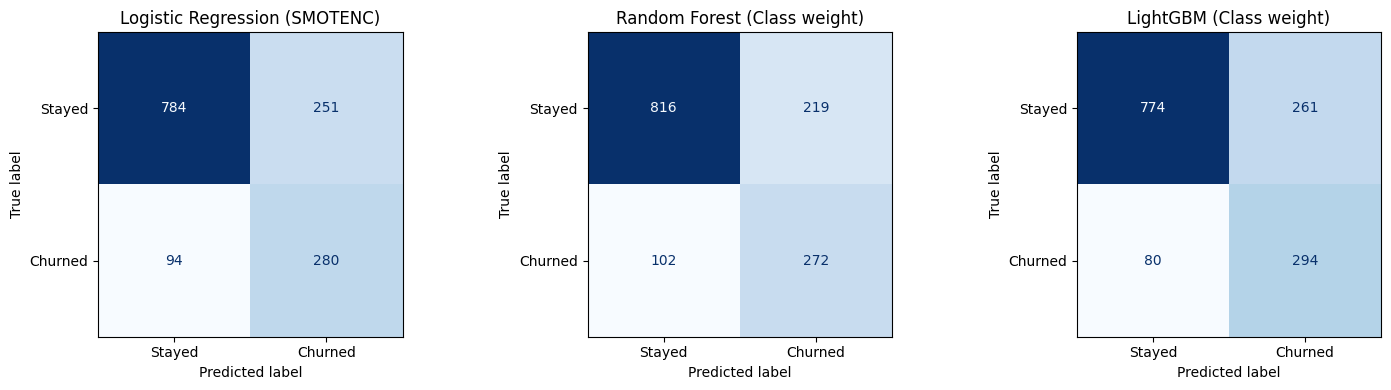

,Logistic Regression,Random Forest,LightGBM
"True Stayed, predicted Stayed",784,816,774
"True Stayed, predicted Churned",251,219,261
"True Churned, predicted Stayed",94,102,80
"True Churned, predicted Churned",280,272,294


In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import os
os.makedirs("Diagrams", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Stayed", "Churned"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(f"{name} ({results_df.loc[name, 'Strategy']})")
plt.tight_layout()
plt.savefig("Diagrams/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(
    {name: cm.ravel() for name, cm in cms.items()},
    index=["True Stayed, predicted Stayed", "True Stayed, predicted Churned",
           "True Churned, predicted Stayed", "True Churned, predicted Churned"]
)

## Interpretation:

The test set has 374 churners and 1035 customers who stayed. The matrices show what each model does with them:

- Logistic Regression caught 280 churners and missed 94. It wrongly flagged 251 customers who stayed, so 531 customers would be contacted.
- Random Forest caught 272 churners and missed 102. It wrongly flagged 219 customers, so 491 would be contacted.
- LightGBM caught 294 churners and missed 80. It wrongly flagged 261 customers, so 555 would be contacted.

LightGBM misses the fewest churners but contacts the most customers. Random Forest contacts the fewest customers but misses the most churners. Which one is better depends on what a missed churner costs compared with a wasted retention offer. This study has no cost figures, so it cannot say that one model is best for a business. This is also why the 0.5 threshold matters, because a company could move it to match its costs.

# Step 11: ROC Curves

The ROC curve shows the trade off between catching churners and wrongly flagging loyal customers across every threshold. The decision threshold used for the table and matrices stays at 0.5. The curve is only for comparing how well the models rank customers.

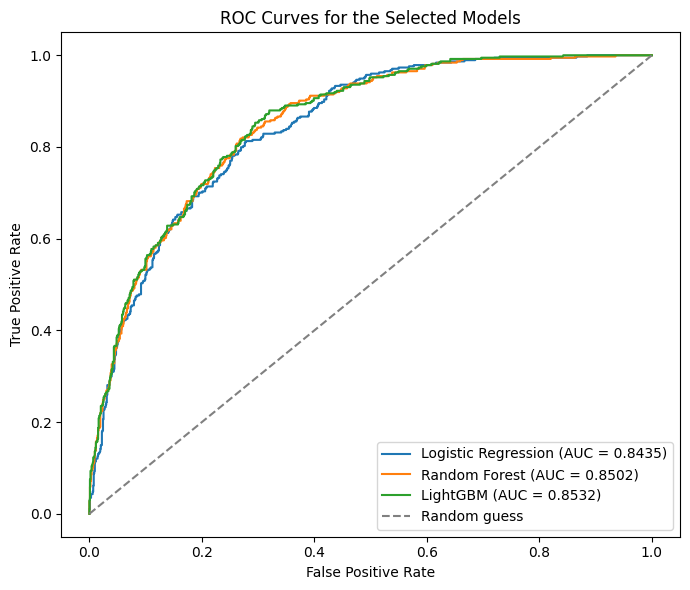

In [15]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))
for name, y_proba in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for the Selected Models")
plt.legend()
plt.tight_layout()
plt.savefig("Diagrams/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Interpretation:

The three curves are very close for most of the range. LightGBM and Random Forest overlap almost completely, and Logistic Regression sits slightly lower in the middle part of the curve (roughly between false positive rates of 0.3 and 0.45). This matches the ROC AUC values of 0.8532, 0.8502 and 0.8435. The differences are small, so the plot supports the idea that all three models rank customers about equally well. The curves do not use the 0.5 threshold, so they show the models' ranking ability on its own.

# Step 12: SHAP Analysis

SHAP is recalculated for the selected LightGBM pipeline, because the corrected tuning may have changed the model. TreeExplainer is used, so this is a model specific TreeSHAP analysis for LightGBM. The test rows are first passed through the fitted preprocessing steps of the pipeline (the sampler is skipped automatically, since it only acts during fitting), and then the explainer works on the final LightGBM model.

SHAP shows what pushed the model's predictions up or down. It does not show that changing a feature would change whether a customer churns.

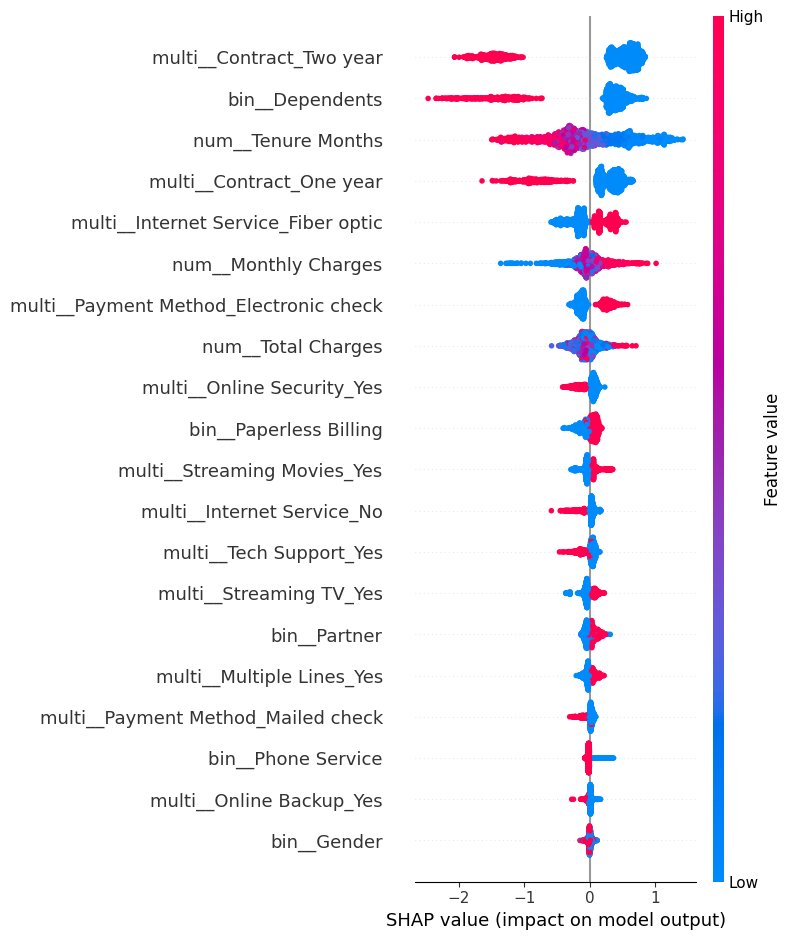

multi__Contract_Two year                  0.7805
bin__Dependents                           0.6521
num__Tenure Months                        0.5021
multi__Contract_One year                  0.4376
multi__Internet Service_Fiber optic       0.2441
num__Monthly Charges                      0.1920
multi__Payment Method_Electronic check    0.1847
num__Total Charges                        0.1209
multi__Online Security_Yes                0.0917
bin__Paperless Billing                    0.0835
dtype: float64

In [16]:
lgbm_pipe = selected["LightGBM"]
lgbm_model = lgbm_pipe.named_steps["clf"]
X_test_proc = lgbm_pipe[:-1].transform(X_test)
if hasattr(X_test_proc, "toarray"):
    X_test_proc = X_test_proc.toarray()

# readable feature names for both pipeline layouts
if "prep" in lgbm_pipe.named_steps:
    names = list(lgbm_pipe.named_steps["prep"].get_feature_names_out())
else:
    ohe = lgbm_pipe.named_steps["post_sampler"].named_transformers_["multi"]
    codes = lgbm_pipe.named_steps["pre_sampler"].named_transformers_["cat"].categories_
    multi_cats = codes[len(binary_cols):]
    names = (["num__" + c for c in numeric_cols] + ["bin__" + c for c in binary_cols])
    for col, cats, kept in zip(multi_cols, multi_cats, ohe.categories_):
        names += [f"multi__{col}_{cats[int(k)]}" for k in kept[1:]]   # drop first removes the first code

X_test_shap = pd.DataFrame(X_test_proc, columns=names)

explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer.shap_values(X_test_shap)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif getattr(shap_values, "ndim", 2) == 3:
    shap_values = shap_values[:, :, 1]

shap.summary_plot(shap_values, X_test_shap, show=False)
plt.tight_layout()
plt.savefig("Diagrams/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=names).sort_values(ascending=False)
mean_abs.head(10).round(4)

## Interpretation:

The SHAP summary plot and the table above rank features by their average effect on the model's predictions (mean absolute SHAP value). This is a TreeSHAP analysis of the selected LightGBM model, so it explains this one model only. The values are on the model's output scale (log odds), where a positive value pushes toward churn and a negative value pushes toward staying. In the plot, red dots are high feature values and blue dots are low ones.

Four features clearly matter more than the rest. Contract Two year (0.7805), Dependents (0.6521), Tenure Months (0.5021) and Contract One year (0.4376) all have much larger average effects than the next feature, Internet Service Fiber optic (0.2441). After the top four, the effects drop quickly and many features have only a small effect.

Customers with a two year contract are pushed strongly toward staying, and customers without one are pushed toward churn. A one year contract works the same way but with a smaller effect. Customers with dependents are also pushed strongly toward staying, and customers without dependents are pushed toward churn. Tenure Months has a wider spread than the contract features, because it is a number and not a yes or no feature. Longer tenure mostly pushes toward staying, and short tenure pushes toward churn, in some cases quite strongly.

A second group of features pushes toward churn. These are Fiber optic internet (0.2441), higher Monthly Charges (0.1920), paying by Electronic check (0.1847) and Paperless Billing (0.0835). Online Security (0.0917), Tech Support and having no internet service push toward staying, but with smaller effects. Total Charges (0.1209) has a mild and mixed effect, and many of its dots sit close to zero. Total Charges and Tenure Months are related, so the model may share their effect between them, which makes each one harder to read on its own. Gender is the lowest of the 20 features shown, and its dots sit very close to zero.

Contract type and tenure match Sinaga and Widianto (2023) and Peng and Peng (2022), who both found them to be strong churn predictors. Dependents ranking second is different, because those studies did not report it as one of their top features. This should be treated as a result to check and not as a firm finding.

SHAP shows what the model used to make its predictions. It does not show what causes churn, and it does not show that changing a feature would stop a customer from leaving.

# Step 13: Save the Run Details for the Report

The full parameter grids, scoring setup and software versions are saved to one text file, so they can go straight into the methodology or an appendix of the report.

In [17]:
import json, platform
run_info = {
    "python": platform.python_version(),
    "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__,
    "imbalanced-learn": imblearn.__version__, "lightgbm": lightgbm.__version__, "shap": shap.__version__,
    "seed": SEED,
    "train_test_split": "stratified 80/20 on Churn Value",
    "cv": f"RepeatedStratifiedKFold, {N_SPLITS} folds x {N_REPEATS} repeats, random_state={SEED}",
    "scoring": list(SCORING.keys()), "refit_metric": REFIT_METRIC, "positive_class": 1,
    "threshold": THRESHOLD,
    "strategies": STRATEGIES,
    "param_grids": {m: {k.replace("clf__", ""): v for k, v in g.items()} for m, g in param_grids.items()},
}
with open("run_details_corrected.json", "w") as f:
    json.dump(run_info, f, indent=2)
print(json.dumps(run_info, indent=2))

{
  "python": "3.11.6",
  "pandas": "3.0.1",
  "numpy": "2.4.2",
  "scikit-learn": "1.8.0",
  "imbalanced-learn": "0.14.2",
  "lightgbm": "4.7.0",
  "shap": "0.51.0",
  "seed": 42,
  "train_test_split": "stratified 80/20 on Churn Value",
  "cv": "RepeatedStratifiedKFold, 5 folds x 3 repeats, random_state=42",
  "scoring": [
    "f1",
    "roc_auc",
    "precision",
    "recall"
  ],
  "refit_metric": "f1",
  "positive_class": 1,
  "threshold": 0.5,
  "strategies": [
    "None",
    "Class weight",
    "SMOTE",
    "SMOTENC"
  ],
  "param_grids": {
    "Logistic Regression": {
      "C": [
        0.01,
        0.1,
        1,
        10
      ],
      "solver": [
        "lbfgs"
      ],
      "max_iter": [
        1000
      ]
    },
    "Random Forest": {
      "n_estimators": [
        100,
        200
      ],
      "max_depth": [
        null,
        10,
        20
      ],
      "min_samples_split": [
        2,
        5
      ]
    },
    "LightGBM": {
      "n_estimators": [


# Step 14: Uncertainty and Subgroup Check (Exploratory)

These two checks use the saved test predictions from Step 9. They do not change any model, setting or threshold. The test set was examined in the first version of this notebook, so the results describe this sample only. They do not make the test set an independent validation set.

First, 95 percent bootstrap intervals are calculated. The 1409 test customers are resampled with replacement 1000 times (seed 42). For each resample, F1 score and AUC ROC are recalculated for each model, with churn (1) as the positive class and a threshold of 0.5 for F1. The interval is the 2.5th to 97.5th percentile of the 1000 results. The same resamples are used for all three models, so the differences between models can be compared directly.

In [18]:
y_true = np.asarray(y_test)
model_names = list(probabilities.keys())
rng = np.random.default_rng(SEED)
B = 1000
idx = rng.integers(0, len(y_true), size=(B, len(y_true)))

boot_f1 = {n: [] for n in model_names}
boot_auc = {n: [] for n in model_names}
for b in idx:
    for n in model_names:
        boot_f1[n].append(f1_score(y_true[b], predictions[n][b]))
        boot_auc[n].append(roc_auc_score(y_true[b], probabilities[n][b]))

rows = []
for n in model_names:
    f_lo, f_hi = np.percentile(boot_f1[n], [2.5, 97.5])
    a_lo, a_hi = np.percentile(boot_auc[n], [2.5, 97.5])
    rows.append({"Model": n,
                 "F1": round(f1_score(y_true, predictions[n]), 4),
                 "F1 95% low": round(f_lo, 4), "F1 95% high": round(f_hi, 4),
                 "AUC-ROC": round(roc_auc_score(y_true, probabilities[n]), 4),
                 "AUC 95% low": round(a_lo, 4), "AUC 95% high": round(a_hi, 4)})
display(pd.DataFrame(rows).set_index("Model"))

pairs = [("LightGBM", "Random Forest"), ("LightGBM", "Logistic Regression"), ("Random Forest", "Logistic Regression")]
diff_rows = []
for a, b in pairs:
    for label, boot, point in [("F1", boot_f1, f1_score), ("AUC-ROC", boot_auc, None)]:
        d = np.array(boot[a]) - np.array(boot[b])
        est = (f1_score(y_true, predictions[a]) - f1_score(y_true, predictions[b])) if point else \
              (roc_auc_score(y_true, probabilities[a]) - roc_auc_score(y_true, probabilities[b]))
        lo, hi = np.percentile(d, [2.5, 97.5])
        diff_rows.append({"Comparison": f"{a} minus {b}", "Metric": label,
                          "Difference": round(est, 4), "95% low": round(lo, 4), "95% high": round(hi, 4)})
display(pd.DataFrame(diff_rows))

,F1,F1 95% low,F1 95% high,AUC-ROC,AUC 95% low,AUC 95% high
Model,,,,,,
Logistic Regression,0.6188,0.5782,0.6524,0.8435,0.8214,0.8642
Random Forest,0.6289,0.5888,0.6630,0.8502,0.8289,0.8694
LightGBM,0.6329,0.5935,0.6653,0.8532,0.8316,0.8723


,Comparison,Metric,Difference,95% low,95% high
0,LightGBM minus Random Forest,F1,0.0040,-0.0133,0.0226
1,LightGBM minus Random Forest,AUC-ROC,0.0030,-0.0031,0.0089
2,LightGBM minus Logistic Regression,F1,0.0142,-0.0108,0.0382
3,LightGBM minus Logistic Regression,AUC-ROC,0.0098,-0.0010,0.0207
4,Random Forest minus Logistic Regression,F1,0.0101,-0.0142,0.0329
5,Random Forest minus Logistic Regression,AUC-ROC,0.0067,-0.0024,0.0153


In [19]:
sub_rows = []
for col in ["Gender", "Senior Citizen"]:
    for g in sorted(X_test[col].unique()):
        m = (X_test[col] == g).values
        for n in model_names:
            tn, fp, fn, tp = confusion_matrix(y_true[m], predictions[n][m], labels=[0, 1]).ravel()
            sub_rows.append({"Group": f"{col} = {g}", "Customers": int(m.sum()), "Churners": int(y_true[m].sum()),
                             "Model": n, "Recall": round(tp / (tp + fn), 3),
                             "Precision": round(tp / (tp + fp), 3),
                             "False positive rate": round(fp / (fp + tn), 3),
                             "Share flagged": round((tp + fp) / m.sum(), 3)})
pd.DataFrame(sub_rows)

,Group,Customers,Churners,Model,Recall,Precision,False positive rate,Share flagged
0,Gender = Female,687,193,Logistic Regression,0.736,0.548,0.237,0.377
1,Gender = Female,687,193,Random Forest,0.710,0.573,0.206,0.348
2,Gender = Female,687,193,LightGBM,0.762,0.540,0.253,0.396
3,Gender = Male,722,181,Logistic Regression,0.762,0.507,0.248,0.377
4,Gender = Male,722,181,Random Forest,0.746,0.536,0.216,0.349
5,Gender = Male,722,181,LightGBM,0.812,0.519,0.251,0.392
6,Senior Citizen = No,1187,276,Logistic Regression,0.717,0.503,0.215,0.332
7,Senior Citizen = No,1187,276,Random Forest,0.688,0.534,0.182,0.300
8,Senior Citizen = No,1187,276,LightGBM,0.746,0.506,0.221,0.343
9,Senior Citizen = Yes,222,98,Logistic Regression,0.837,0.599,0.444,0.617


# Conclusion

This notebook compared Logistic Regression, Random Forest and LightGBM for predicting customer churn on the Telco dataset. It also fixed the validation problems found in the first version, where preprocessing and SMOTE were applied before the cross validation.

The correction mattered. The cross validation F1 scores dropped from 0.79 to 0.86 down to 0.64 to 0.65 and are now close to the test F1 scores of 0.62 to 0.63. This fits with the old scores being too high, but the correction changed several things at once, so this notebook cannot say how much each one contributed.

On SRQ1, which model performs best, there is no clear winner. LightGBM had the highest test F1 (0.6329) and ROC AUC (0.8532), but Random Forest was only 0.004 behind on F1, and Logistic Regression was 0.014 behind. The models also swapped places between cross validation and the test set. The models differ more in their mistakes than in their scores. LightGBM caught the most churners (294 of 374) but contacted the most customers (555), while Random Forest contacted the fewest (491) but missed the most churners. Which one is better depends on the cost of a missed churner compared with the cost of a wasted offer, and this study does not have those costs.

On SRQ2, which features matter most, the SHAP analysis of LightGBM showed contract type, dependents and tenure as the strongest signs of a customer staying. Fiber optic internet, higher monthly charges and electronic check payments pointed toward churn. This agrees with Sinaga and Widianto (2023) and Peng and Peng (2022) for contract type and tenure. These are patterns in the model's predictions and not proof of what causes churn. The importance of Dependents should be checked further.

On SRQ3, how imbalance handling affects performance, handling the imbalance in any way raised F1 at the 0.5 threshold compared with doing nothing, by about 0.02 to 0.06. ROC AUC barely changed, so the gain came from predicting churn more often (higher recall, lower precision) and not from better ranking. No strategy showed a consistent, meaningful advantage and the differences were small, so this study does not support saying that SMOTE improved performance.

These results have limits. They come from one dataset, one train and test split, and small parameter grids. The test set has only 374 churners, F1 depends on the 0.5 threshold, and the differences between models are small. The test results from the first version were seen before this rerun, and the plan was fixed before the corrected cross validation was run. The conclusions should be treated as true for this experiment and not as a general ranking of the three algorithms.

# Reference List

Peng, K. and Peng, Y., 2022. Research on telecom customer churn prediction based on GA-XGBoost and SHAP. Journal of Computer and Communications, 10(1), pp.107–120. Available at: https://www.scirp.org/journal/paperinformation?paperid=121175. Accessed on: 11/06/2026

Sana, J.K., Abedin, M.Z., Rahman, M.S. and Rahman, M.S., 2022. A novel customer churn prediction model for the telecommunication industry using data transformation methods and feature selection. PLOS ONE, 17(12), p.e0278095. Available at: https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0278095. Accessed on: 11/06/2026

Sinaga, R. and Widianto, S., 2023. Understanding telecommunication customer churn: insights from LightGBM predictive modelling and SHAP feature interpretation. ASEAN Marketing Journal, 15(1), article 4. Available at: https://scholarhub.ui.ac.id/amj/vol15/iss1/4/. Accessed on: 11/06/2026

Suguna, R. et al., 2025. Mitigating class imbalance in churn prediction with ensemble methods and SMOTE. Scientific Reports, 15(1), p.16256. Available at: https://doi.org/10.1038/s41598-025-01031-0. Accessed on: 11/06/2026